In [1]:

%pip install -q scikit-learn imbalanced-learn lightgbm


In [2]:

import numpy as np
import pandas as pd
import joblib
import warnings

from pathlib import Path
from scipy import sparse

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from lightgbm import LGBMClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

warnings.filterwarnings("ignore", category=UserWarning)

BASE_DIR = Path(
    "/content/drive/MyDrive/Colab Notebooks/data"
)

PROCESSED_DIR = BASE_DIR / "processed"
RESAMPLED_DIR = BASE_DIR / "resampled"
SELECTION_DIR = BASE_DIR / "feature_selection"

RESULTS_DIR = Path(
    "/content/drive/MyDrive/Colab Notebooks/results"
)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

feature_groups = ["Radiom", "RadioClin", "RadioClinLab"]
targets = ["ICU", "mechanical_ventilation", "death"]

print("Paths configured.")
print("Results directory:", RESULTS_DIR)


Paths configured.
Results directory: /content/drive/MyDrive/Colab Notebooks/results


In [3]:

def load_matrix(directory, name):
    npy_path = directory / f"{name}.npy"
    npz_path = directory / f"{name}.npz"

    if npy_path.exists():
        return np.load(npy_path)

    if npz_path.exists():
        return sparse.load_npz(npz_path)

    raise FileNotFoundError(
        f"Could not find {name}.npy or {name}.npz "
        f"in {directory}"
    )

def load_selected_indices(group, target):
    path = (
        SELECTION_DIR
        / f"{group}_{target}_selected_indices.npy"
    )

    if not path.exists():
        raise FileNotFoundError(
            f"Selected indices not found: {path}. "
            "Complete Step 8 first."
        )

    return np.load(path).astype(int)

Y_train = pd.read_csv(PROCESSED_DIR / "Y_train.csv")
Y_test = pd.read_csv(PROCESSED_DIR / "Y_test.csv")

print("Training labels:", Y_train.shape)
print("Test labels:", Y_test.shape)


Training labels: (1680, 3)
Test labels: (720, 3)


In [4]:

def create_models():
    return {
        "Logistic Regression": LogisticRegression(
            max_iter=2000,
            random_state=42
        ),

        "Random Forest": RandomForestClassifier(
            n_estimators=150,
            min_samples_leaf=2,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ),

        "SVM": SVC(
            kernel="rbf",
            probability=True,
            class_weight="balanced",
            random_state=42
        ),

        "MLP": MLPClassifier(
            hidden_layer_sizes=(64, 32),
            max_iter=300,
            early_stopping=True,
            random_state=42
        ),

        "LightGBM": LGBMClassifier(
            n_estimators=150,
            learning_rate=0.05,
            num_leaves=15,
            verbosity=-1,
            random_state=42,
            n_jobs=-1
        )
    }

print("Models configured:", list(create_models().keys()))


Models configured: ['Logistic Regression', 'Random Forest', 'SVM', 'MLP', 'LightGBM']


In [5]:

results = []
trained_models = {}

for group in feature_groups:

    print(f"\n{'=' * 65}")
    print(f"FEATURE GROUP: {group}")
    print("=" * 65)

    for target in targets:

        print(f"\nTarget: {target}")

        # Feature indices selected using original training data
        selected_indices = load_selected_indices(group, target)

        # Load resampled training matrix
        X_resampled = load_matrix(
            RESAMPLED_DIR,
            f"{group}_{target}_X_train_resampled"
        )

        # Load original test matrix with selected features
        X_test_selected = load_matrix(
            SELECTION_DIR,
            f"{group}_{target}_X_test_selected"
        )

        y_resampled = np.load(
            RESAMPLED_DIR
            / f"{group}_{target}_y_train_resampled.npy"
        ).astype(int)

        y_test = Y_test[target].astype(int).to_numpy()

        # Apply LASSO-selected indices to resampled training data
        X_train_selected = X_resampled[:, selected_indices]

        assert X_train_selected.shape[1] == X_test_selected.shape[1]
        assert X_test_selected.shape[0] == len(y_test)

        print("Training shape:", X_train_selected.shape)
        print("Testing shape:", X_test_selected.shape)

        for model_name, model in create_models().items():

            print(f"Training {model_name}...")

            model.fit(X_train_selected, y_resampled)

            predictions = model.predict(X_test_selected)
            probabilities = model.predict_proba(
                X_test_selected
            )[:, 1]

            row = {
                "Feature Group": group,
                "Target": target,
                "Model": model_name,
                "Selected Features": len(selected_indices),
                "Train Rows After SMOTEENN": len(y_resampled),
                "Accuracy": accuracy_score(y_test, predictions),
                "Precision": precision_score(
                    y_test, predictions, zero_division=0
                ),
                "Recall": recall_score(
                    y_test, predictions, zero_division=0
                ),
                "F1 Score": f1_score(
                    y_test, predictions, zero_division=0
                ),
                "ROC-AUC": roc_auc_score(
                    y_test, probabilities
                ),
                "PR-AUC (Average Precision)": average_precision_score(
                    y_test, probabilities
                )
            }

            results.append(row)

            trained_models[
                (group, target, model_name)
            ] = model

            print(
                f"ROC-AUC: {row['ROC-AUC']:.3f} | "
                f"F1: {row['F1 Score']:.3f}"
            )

results_df = pd.DataFrame(results)

print("\nAll model experiments completed.")
display(results_df.head(10))



FEATURE GROUP: Radiom

Target: ICU
Training shape: (1170, 113)
Testing shape: (720, 113)
Training Logistic Regression...
ROC-AUC: 0.717 | F1: 0.457
Training Random Forest...
ROC-AUC: 0.631 | F1: 0.454
Training SVM...
ROC-AUC: 0.632 | F1: 0.457
Training MLP...
ROC-AUC: 0.615 | F1: 0.455
Training LightGBM...
ROC-AUC: 0.644 | F1: 0.458

Target: mechanical_ventilation
Training shape: (1218, 115)
Testing shape: (720, 115)
Training Logistic Regression...
ROC-AUC: 0.695 | F1: 0.460
Training Random Forest...
ROC-AUC: 0.665 | F1: 0.463
Training SVM...
ROC-AUC: 0.569 | F1: 0.465
Training MLP...
ROC-AUC: 0.695 | F1: 0.464
Training LightGBM...
ROC-AUC: 0.629 | F1: 0.483

Target: death
Training shape: (1442, 109)
Testing shape: (720, 109)
Training Logistic Regression...
ROC-AUC: 0.701 | F1: 0.303
Training Random Forest...
ROC-AUC: 0.693 | F1: 0.293
Training SVM...
ROC-AUC: 0.657 | F1: 0.304
Training MLP...
ROC-AUC: 0.690 | F1: 0.294
Training LightGBM...
ROC-AUC: 0.661 | F1: 0.307

FEATURE GROUP: R

,Feature Group,Target,Model,Selected Features,Train Rows After SMOTEENN,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC (Average Precision)
0,Radiom,ICU,Logistic Regression,113,1170,0.305556,0.296192,0.995261,0.456522,0.716887,0.502241
1,Radiom,ICU,Random Forest,113,1170,0.294444,0.293463,1.000000,0.453763,0.630620,0.368215
2,Radiom,ICU,SVM,113,1170,0.302778,0.295933,1.000000,0.456710,0.632231,0.369943
3,Radiom,ICU,MLP,113,1170,0.298611,0.294693,1.000000,0.455232,0.615136,0.423261
4,Radiom,ICU,LightGBM,113,1170,0.305556,0.296765,1.000000,0.457701,0.644215,0.377242
5,Radiom,mechanical_ventilation,Logistic Regression,115,1218,0.315278,0.300429,0.981308,0.460022,0.695098,0.512505
6,Radiom,mechanical_ventilation,Random Forest,115,1218,0.313889,0.301700,0.995327,0.463043,0.665403,0.407005
7,Radiom,mechanical_ventilation,SVM,115,1218,0.326389,0.304473,0.985981,0.465270,0.569235,0.336600
8,Radiom,mechanical_ventilation,MLP,115,1218,0.316667,0.302557,0.995327,0.464052,0.694812,0.519741
9,Radiom,mechanical_ventilation,LightGBM,115,1218,0.379167,0.321045,0.976636,0.483237,0.629276,0.355969


In [6]:

results_path = RESULTS_DIR / "model_comparison.csv"

results_df.to_csv(results_path, index=False)

MODEL_DIR = RESULTS_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

for (group, target, model_name), model in trained_models.items():

    safe_model_name = (
        model_name.lower()
        .replace(" ", "_")
    )

    filename = f"{group}_{target}_{safe_model_name}.joblib"

    joblib.dump(model, MODEL_DIR / filename)

print("Metrics saved to:", results_path)
print("Models saved to:", MODEL_DIR)
print("Number of trained models:", len(trained_models))


Metrics saved to: /content/drive/MyDrive/Colab Notebooks/results/model_comparison.csv
Models saved to: /content/drive/MyDrive/Colab Notebooks/results/models
Number of trained models: 45


In [7]:

for target in targets:

    print(f"\n{'=' * 60}")
    print(f"PERFORMANCE FOR: {target}")
    print("=" * 60)

    target_results = results_df[
        results_df["Target"] == target
    ].sort_values("ROC-AUC", ascending=False)

    display(
        target_results[
            [
                "Feature Group",
                "Model",
                "Selected Features",
                "Accuracy",
                "F1 Score",
                "ROC-AUC",
                "PR-AUC (Average Precision)"
            ]
        ].round(3)
    )



PERFORMANCE FOR: ICU


,Feature Group,Model,Selected Features,Accuracy,F1 Score,ROC-AUC,PR-AUC (Average Precision)
30,RadioClinLab,Logistic Regression,148,0.321,0.463,0.721,0.509
0,Radiom,Logistic Regression,113,0.306,0.457,0.717,0.502
33,RadioClinLab,MLP,148,0.315,0.461,0.714,0.493
15,RadioClin,Logistic Regression,131,0.308,0.459,0.684,0.460
31,RadioClinLab,Random Forest,148,0.301,0.456,0.681,0.409
34,RadioClinLab,LightGBM,148,0.336,0.469,0.670,0.389
4,Radiom,LightGBM,113,0.306,0.458,0.644,0.377
2,Radiom,SVM,113,0.303,0.457,0.632,0.370
16,RadioClin,Random Forest,131,0.296,0.454,0.632,0.365
1,Radiom,Random Forest,113,0.294,0.454,0.631,0.368



PERFORMANCE FOR: mechanical_ventilation


,Feature Group,Model,Selected Features,Accuracy,F1 Score,ROC-AUC,PR-AUC (Average Precision)
35,RadioClinLab,Logistic Regression,143,0.343,0.467,0.737,0.552
20,RadioClin,Logistic Regression,129,0.321,0.463,0.712,0.538
38,RadioClinLab,MLP,143,0.315,0.464,0.711,0.535
5,Radiom,Logistic Regression,115,0.315,0.460,0.695,0.513
8,Radiom,MLP,115,0.317,0.464,0.695,0.520
23,RadioClin,MLP,129,0.314,0.462,0.691,0.519
21,RadioClin,Random Forest,129,0.311,0.461,0.686,0.423
24,RadioClin,LightGBM,129,0.333,0.467,0.671,0.403
6,Radiom,Random Forest,115,0.314,0.463,0.665,0.407
36,RadioClinLab,Random Forest,143,0.319,0.464,0.665,0.404



PERFORMANCE FOR: death


,Feature Group,Model,Selected Features,Accuracy,F1 Score,ROC-AUC,PR-AUC (Average Precision)
41,RadioClinLab,Random Forest,145,0.200,0.294,0.730,0.317
40,RadioClinLab,Logistic Regression,145,0.240,0.303,0.722,0.352
43,RadioClinLab,MLP,145,0.228,0.300,0.713,0.354
44,RadioClinLab,LightGBM,145,0.272,0.311,0.713,0.276
25,RadioClin,Logistic Regression,128,0.224,0.297,0.709,0.334
10,Radiom,Logistic Regression,109,0.240,0.303,0.701,0.335
26,RadioClin,Random Forest,128,0.183,0.290,0.694,0.270
28,RadioClin,MLP,128,0.199,0.290,0.694,0.312
11,Radiom,Random Forest,109,0.194,0.293,0.693,0.270
13,Radiom,MLP,109,0.214,0.294,0.690,0.319


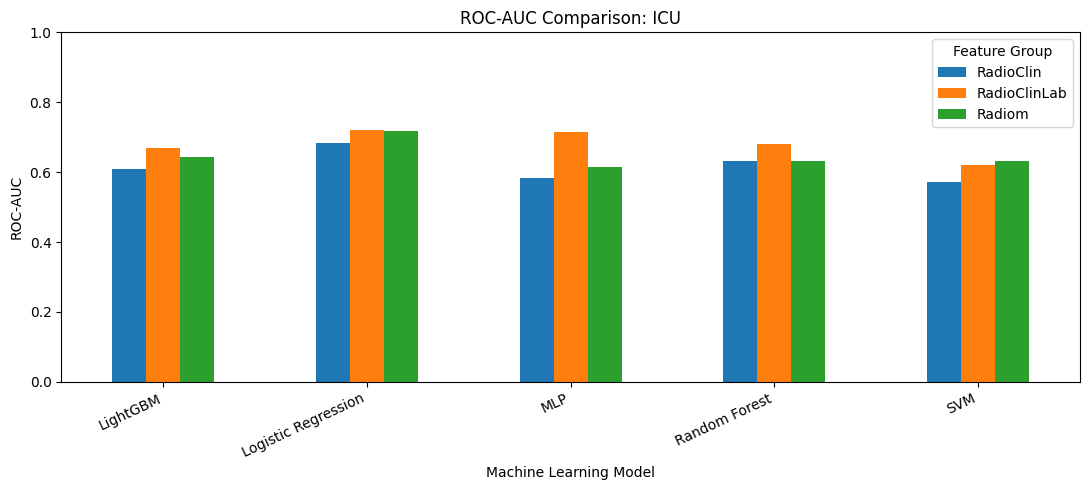

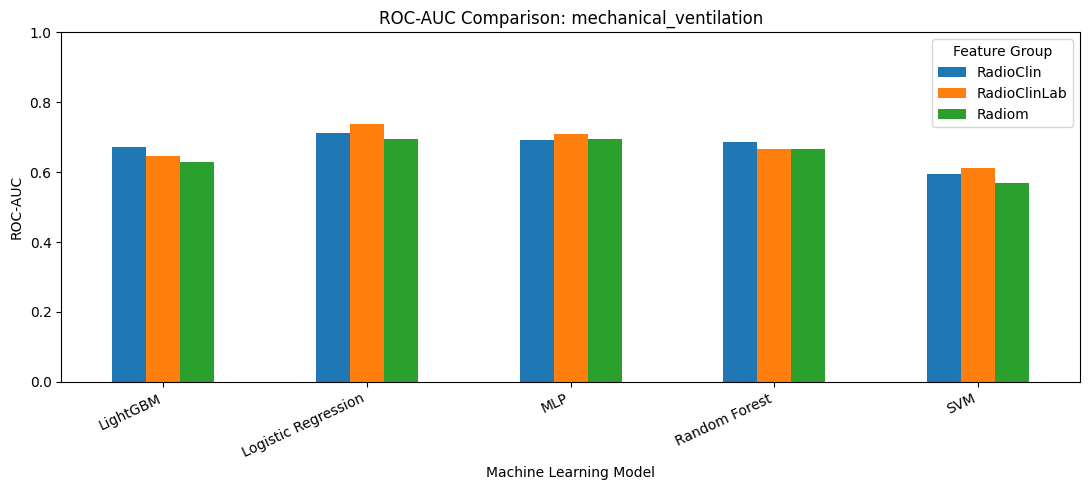

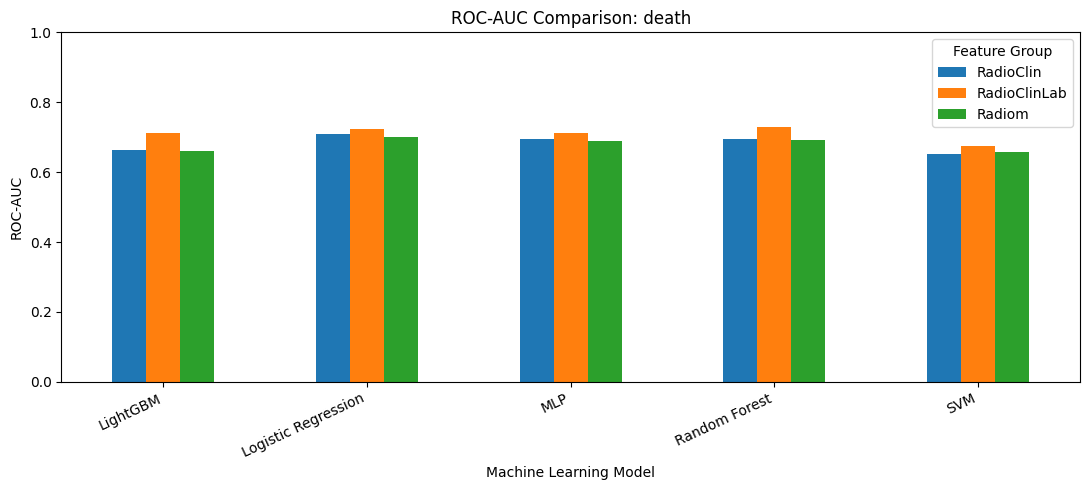

In [8]:

import matplotlib.pyplot as plt

for target in targets:

    subset = results_df[
        results_df["Target"] == target
    ].copy()

    pivot = subset.pivot(
        index="Model",
        columns="Feature Group",
        values="ROC-AUC"
    )

    ax = pivot.plot(
        kind="bar",
        figsize=(11, 5)
    )

    ax.set_title(f"ROC-AUC Comparison: {target}")
    ax.set_xlabel("Machine Learning Model")
    ax.set_ylabel("ROC-AUC")
    ax.set_ylim(0, 1)
    ax.legend(title="Feature Group")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()
